# Employee Attrition & Workforce Analytics using Python

This notebook investigates factors associated with employee attrition in the IBM HR Analytics Employee Attrition & Performance dataset.

## Business questions
- What is the overall attrition rate?
- Which departments and job roles have higher attrition?
- How is overtime associated with attrition?
- Do monthly income, job satisfaction, distance from home, age, and work-life balance differ by attrition?
- What actionable workforce recommendations are supported by the analysis?

## How to run in Google Colab
1. Upload this notebook to Google Drive and open it with Google Colab.
2. Run cells from top to bottom.
3. When prompted, upload your Kaggle API token (`kaggle.json`) **or** use the alternative direct Kaggle download method described in the setup cell.
4. At the end, the notebook creates `EDA_Report.pdf`, `Presentation.pptx`, cleaned data, and figures in the `outputs/` folder.
5. Upload the notebook, README, report, slides, and (if permitted) dataset/reference link to GitHub.

**Important:** This is observational analysis. Associations are not proof that a factor causes attrition. Do not treat group differences as predictions about individual employees.


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pptx import Presentation
from pptx.util import Pt

In [6]:
# 1. Setup
!pip -q install kagglehub pandas numpy matplotlib seaborn scipy reportlab python-pptx

import os, glob, warnings, textwrap, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

print("Setup complete. Output folder:", OUTPUT_DIR.resolve())


Setup complete. Output folder: /content/outputs


## 2. Download and load the dataset

The dataset is hosted on Kaggle. The next cell attempts to download it using `kagglehub`. If Kaggle access is blocked in your Colab session, download `WA_Fn-UseC_-HR-Employee-Attrition.csv` manually from the dataset page and upload it to the Colab session, then rerun the loading cell.

Dataset page: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


In [7]:
# Download with KaggleHub. If this fails, manually upload the CSV from Kaggle.
csv_path = None
try:
    import kagglehub
    dataset_dir = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
    candidates = glob.glob(os.path.join(dataset_dir, "**", "*.csv"), recursive=True)
    if candidates:
        csv_path = candidates[0]
        print("Downloaded CSV:", csv_path)
except Exception as e:
    print("Automatic download was not available:", repr(e))
    print("Fallback: upload the CSV from Kaggle into the Colab session.")

if csv_path is None:
    from google.colab import files
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith(".csv")]
    if not candidates:
        raise FileNotFoundError("No CSV uploaded. Upload the IBM HR attrition CSV and rerun this cell.")
    csv_path = candidates[0]

df_raw = pd.read_csv(csv_path)
df = df_raw.copy()
print("Dataset loaded:", df.shape)
display(df.head())


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Downloaded CSV: /kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv
Dataset loaded: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3. Data understanding and data dictionary

We inspect the dataset dimensions, types, summary statistics, and columns. The dataset includes employee demographics, job information, compensation, satisfaction ratings, and the target `Attrition` (Yes/No). `EmployeeNumber` is an identifier, not a meaningful numeric measure.


In [8]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values,
                      "missing_count": df.isna().sum().values,
                      "missing_pct": (df.isna().mean().values*100).round(2)}))
display(df.describe(include="all").T)
print("Column names:")
print(df.columns.tolist())

# A lightweight data dictionary inferred from field names; confirm with the dataset documentation.
data_dictionary = pd.DataFrame({
    "column": df.columns,
    "data_type": [str(df[c].dtype) for c in df.columns],
    "description": [
        "Employee attrition status (target)" if c == "Attrition" else
        "Unique employee identifier; exclude from analysis" if c in ["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"] else
        "Employee-related field; see IBM HR dataset documentation for exact definition"
        for c in df.columns
    ]
})
display(data_dictionary)
data_dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)


Rows: 1470 | Columns: 35


,column,dtype,missing_count,missing_pct
0,Age,int64,0,0.0
1,Attrition,object,0,0.0
2,BusinessTravel,object,0,0.0
3,DailyRate,int64,0,0.0
4,Department,object,0,0.0
5,DistanceFromHome,int64,0,0.0
6,Education,int64,0,0.0
7,EducationField,object,0,0.0
8,EmployeeCount,int64,0,0.0
9,EmployeeNumber,int64,0,0.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


,column,data_type,description
0,Age,int64,Employee-related field; see IBM HR dataset doc...
1,Attrition,object,Employee attrition status (target)
2,BusinessTravel,object,Employee-related field; see IBM HR dataset doc...
3,DailyRate,int64,Employee-related field; see IBM HR dataset doc...
4,Department,object,Employee-related field; see IBM HR dataset doc...
5,DistanceFromHome,int64,Employee-related field; see IBM HR dataset doc...
6,Education,int64,Employee-related field; see IBM HR dataset doc...
7,EducationField,object,Employee-related field; see IBM HR dataset doc...
8,EmployeeCount,int64,Unique employee identifier; exclude from analysis
9,EmployeeNumber,int64,Unique employee identifier; exclude from analysis


## 4. Data quality checks and cleaning

The checks below report missing values, exact duplicate rows, duplicate employee IDs, low-cardinality fields, and invalid target labels. We do not automatically delete unusual observations: possible outliers are investigated and retained unless there is evidence of an error.


In [9]:
# Missing values and duplicates
missing = df.isna().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing[missing > 0].to_frame("missing_count") if (missing > 0).any() else pd.DataFrame({"status":["No missing values detected"]}))

exact_duplicates = int(df.duplicated().sum())
print("Exact duplicate rows:", exact_duplicates)
if "EmployeeNumber" in df.columns:
    print("Duplicate EmployeeNumber values:", int(df["EmployeeNumber"].duplicated().sum()))

# Trim text values and standardize target label formatting if present
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

if "Attrition" not in df.columns:
    raise KeyError("Expected target column 'Attrition' was not found. Check that the correct IBM HR CSV was loaded.")

print("Attrition labels:", df["Attrition"].value_counts(dropna=False).to_dict())
print("Rows with missing target:", int(df["Attrition"].isna().sum()))

# Dataset-specific constant/identifier columns are not useful for correlation or most plots.
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Constant columns:", constant_cols)

# Validate common expected ranges, without changing data automatically
for col in ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears", "YearsAtCompany"]:
    if col in df.columns:
        print(f"{col}: min={df[col].min()}, max={df[col].max()}, negative_count={(df[col] < 0).sum()}")


Missing values by column:


,status
0,No missing values detected


Exact duplicate rows: 0
Duplicate EmployeeNumber values: 0
Attrition labels: {'No': 1233, 'Yes': 237}
Rows with missing target: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Age: min=18, max=60, negative_count=0
MonthlyIncome: min=1009, max=19999, negative_count=0
DistanceFromHome: min=1, max=29, negative_count=0
TotalWorkingYears: min=0, max=40, negative_count=0
YearsAtCompany: min=0, max=40, negative_count=0


## 5. Feature groups and overall attrition

`Attrition` is treated as a categorical outcome. The attrition rate is the percentage of records marked `Yes`. Counts and rates are shown together because a high rate in a small group may represent fewer employees than a moderate rate in a large group.


Overall attrition rate: 16.12% (237 of 1470 records)


,Employees
Attrition,
No,1233
Yes,237


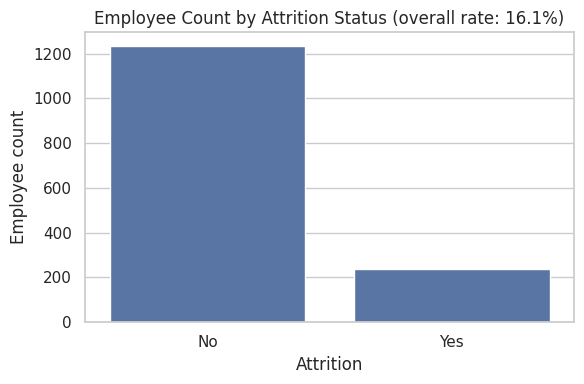

In [10]:
df["Attrition"] = df["Attrition"].astype(str).str.strip().str.title()
if not set(df["Attrition"].dropna().unique()).issubset({"Yes", "No"}):
    print("Warning: unexpected Attrition labels found:", df["Attrition"].unique())

attrition_counts = df["Attrition"].value_counts()
attrition_rate = 100 * (df["Attrition"] == "Yes").mean()
print(f"Overall attrition rate: {attrition_rate:.2f}% ({int((df['Attrition']=='Yes').sum())} of {len(df)} records)")
display(attrition_counts.rename_axis("Attrition").to_frame("Employees"))

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Attrition", order=["No","Yes"])
plt.title(f"Employee Count by Attrition Status (overall rate: {attrition_rate:.1f}%)")
plt.xlabel("Attrition")
plt.ylabel("Employee count")
plt.tight_layout()
plt.savefig(FIG_DIR/"01_attrition_count.png", dpi=160)
plt.show()


## 6. Univariate numerical analysis — histograms

At least three histograms are required. This section selects available numeric fields and visualizes Age, MonthlyIncome, and DistanceFromHome when present. Skewed income distributions are expected in many workforce datasets, so compare medians and distributions as well as means.


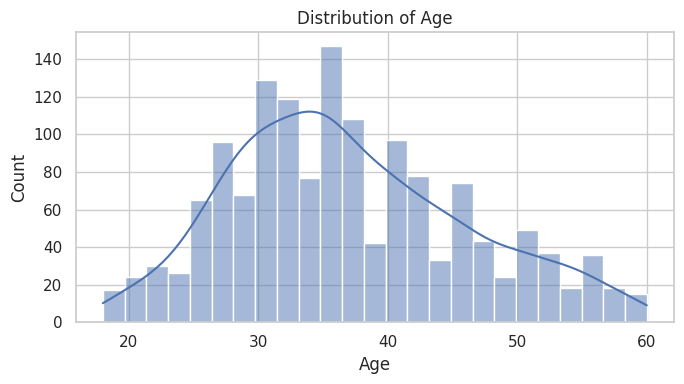

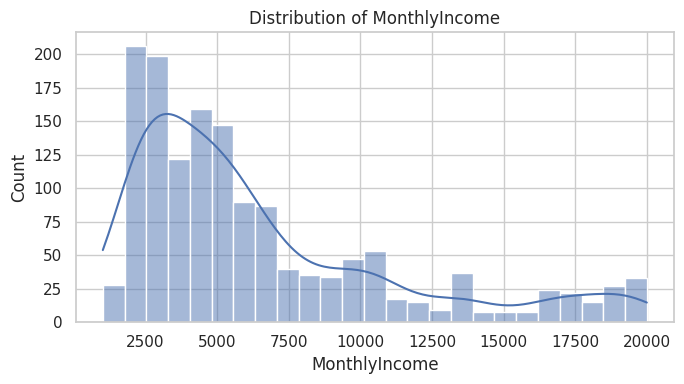

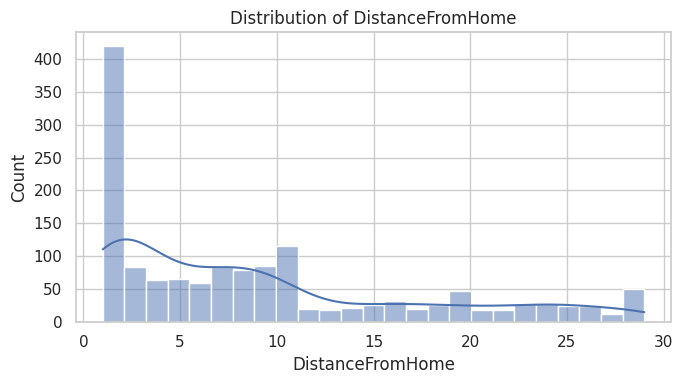

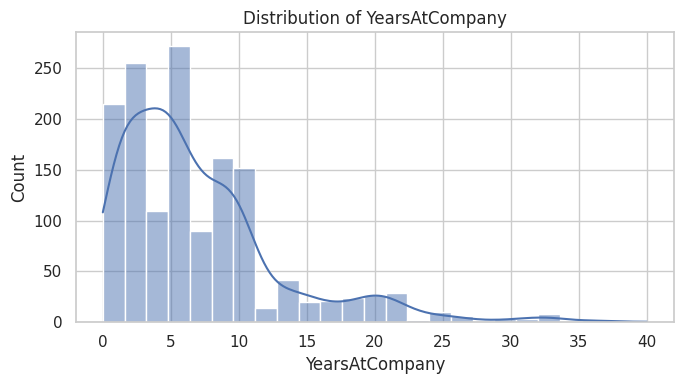

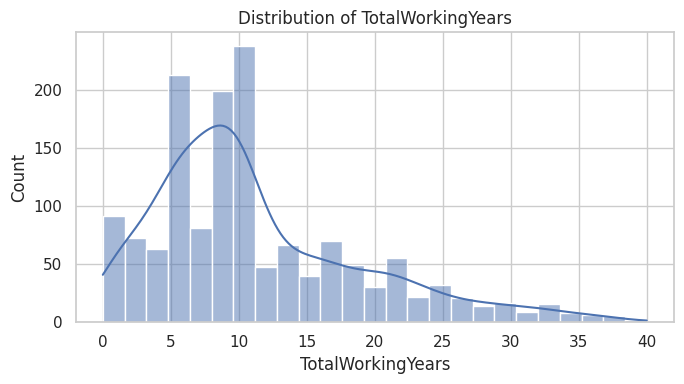

In [11]:
hist_cols = [c for c in ["Age", "MonthlyIncome", "DistanceFromHome", "YearsAtCompany", "TotalWorkingYears"] if c in df.columns][:5]
for i, col in enumerate(hist_cols, start=1):
    plt.figure(figsize=(7,4))
    sns.histplot(data=df, x=col, bins=25, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"hist_{col}.png", dpi=160)
    plt.show()


## 7. Numerical comparison and outlier analysis — box plots

Box plots summarize medians, interquartile ranges, and potential outliers. Outliers are not automatically errors; employees with unusually high income or tenure may be valid cases.


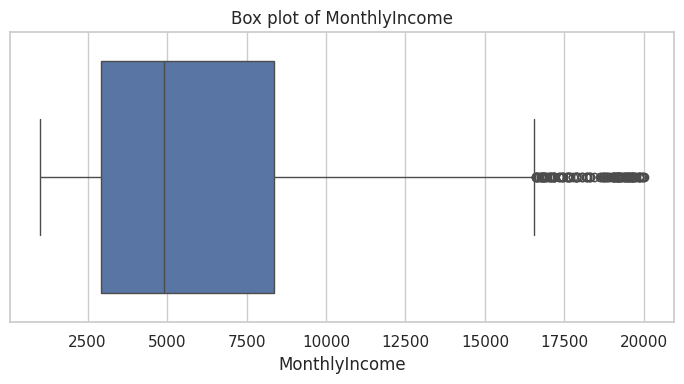

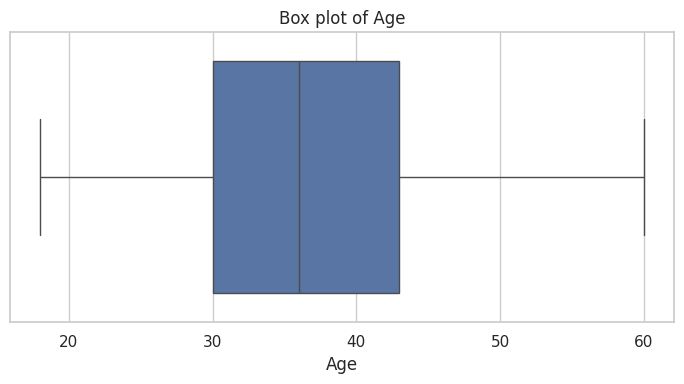

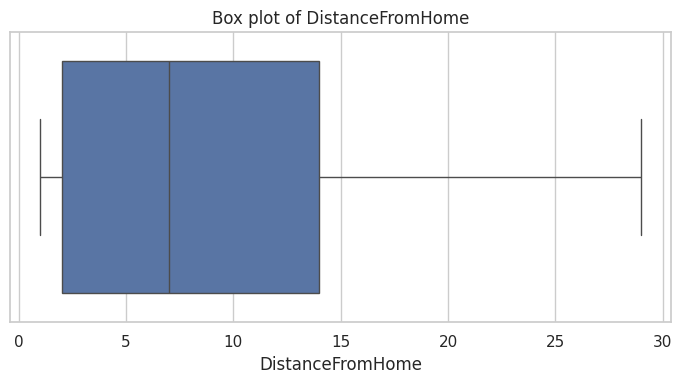

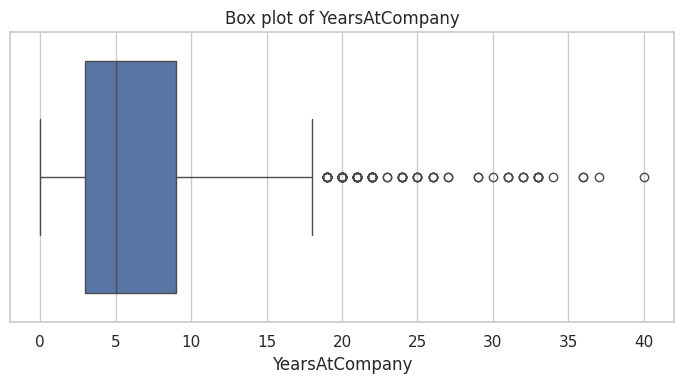

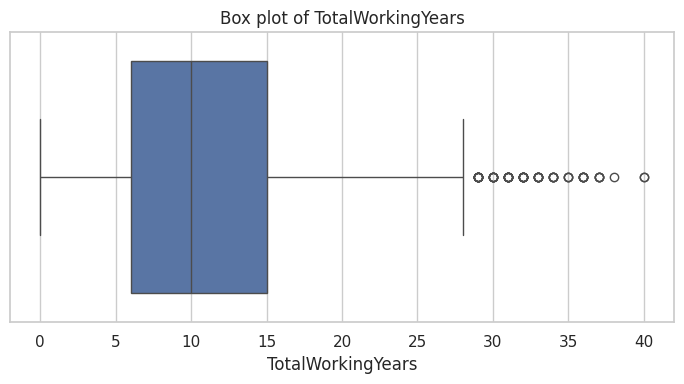

,column,lower_fence,upper_fence,outlier_count,outlier_pct
11,TrainingTimesLastYear,0.500,4.500,238,16.19
6,MonthlyIncome,-5291.000,16581.000,114,7.76
14,YearsSinceLastPromotion,-4.500,7.500,107,7.28
12,YearsAtCompany,-6.000,18.000,104,7.07
10,TotalWorkingYears,-7.500,28.500,63,4.29
8,NumCompaniesWorked,-3.500,8.500,52,3.54
13,YearsInCurrentRole,-5.500,14.500,21,1.43
15,YearsWithCurrManager,-5.500,14.500,14,0.95
7,MonthlyRate,-10574.750,39083.250,0,0.00
5,JobLevel,-2.000,6.000,0,0.00


In [12]:
box_cols = [c for c in ["MonthlyIncome", "Age", "DistanceFromHome", "YearsAtCompany", "TotalWorkingYears"] if c in df.columns][:5]
for col in box_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df, x=col)
    plt.title(f"Box plot of {col}")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"box_{col}.png", dpi=160)
    plt.show()

# IQR outlier counts (diagnostic only)
outlier_rows = []
for col in df.select_dtypes(include=np.number).columns:
    if col in ["EmployeeNumber", "EmployeeCount", "StandardHours", "Over18"]:
        continue
    s = df[col].dropna()
    if s.nunique() < 5:
        continue
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    outlier_rows.append({"column": col, "lower_fence": low, "upper_fence": high,
                         "outlier_count": int(((s < low) | (s > high)).sum()),
                         "outlier_pct": round(100*((s < low) | (s > high)).mean(), 2)})
outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)
display(outlier_summary)
outlier_summary.to_csv(OUTPUT_DIR/"outlier_summary.csv", index=False)


## 8. Categorical analysis — bar charts and count plots

This section compares attrition across department, job role, overtime, and business travel where available. Rates are calculated within each group (`Yes` divided by that group's total), not as a percentage of all attrition cases.


### Department: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
Department,,,
Sales,446,20.63,92
Human Resources,63,19.05,12
Research & Development,961,13.84,133


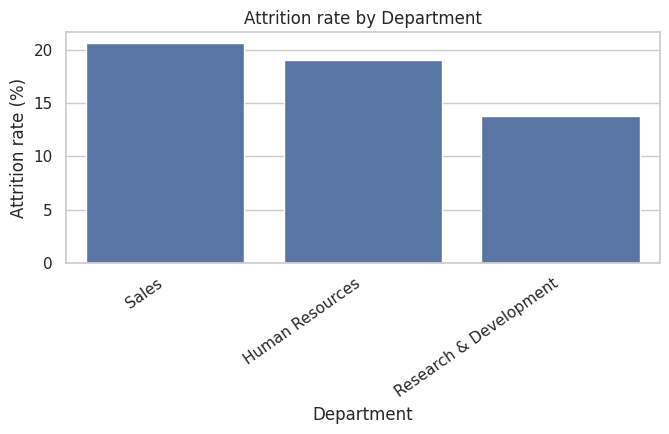

### JobRole: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
JobRole,,,
Sales Representative,83,39.76,33
Laboratory Technician,259,23.94,62
Human Resources,52,23.08,12
Sales Executive,326,17.48,57
Research Scientist,292,16.10,47
Manufacturing Director,145,6.90,10
Healthcare Representative,131,6.87,9
Manager,102,4.90,5
Research Director,80,2.50,2


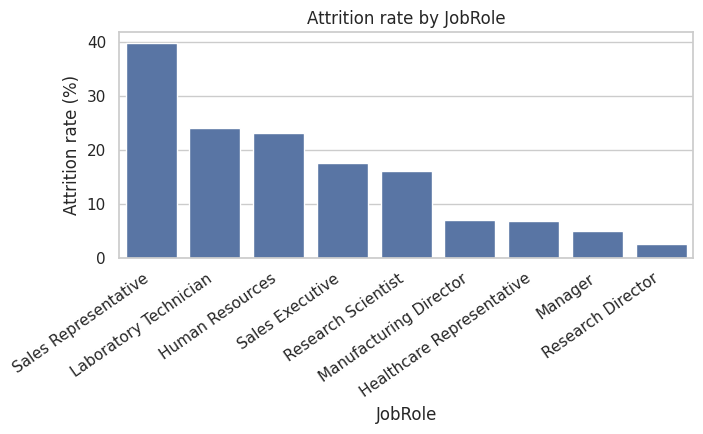

### OverTime: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
OverTime,,,
Yes,416,30.53,127
No,1054,10.44,110


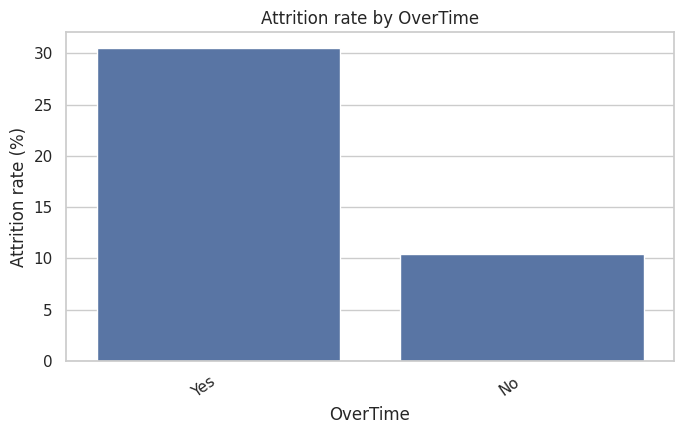

### BusinessTravel: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
BusinessTravel,,,
Travel_Frequently,277,24.91,69
Travel_Rarely,1043,14.96,156
Non-Travel,150,8.00,12


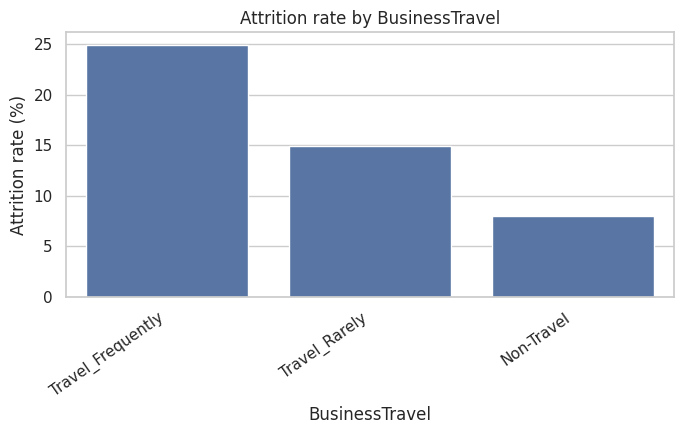

### MaritalStatus: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
MaritalStatus,,,
Single,470,25.53,120
Married,673,12.48,84
Divorced,327,10.09,33


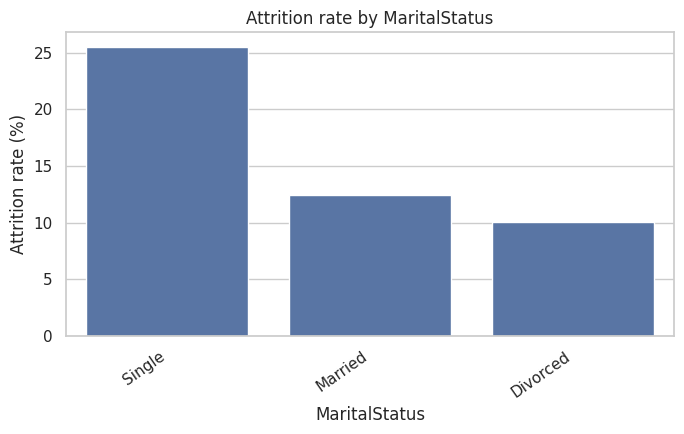

### Gender: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
Gender,,,
Male,882,17.01,150
Female,588,14.80,87


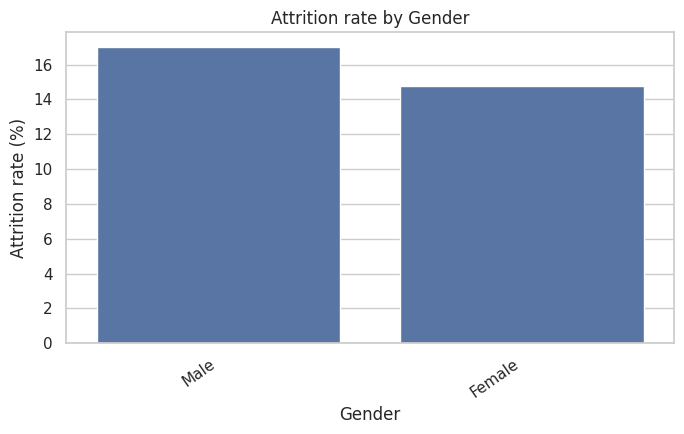

### EducationField: attrition rate by group

,employees,attrition_rate_pct,attrition_yes
EducationField,,,
Human Resources,27,25.93,7
Technical Degree,132,24.24,32
Marketing,159,22.01,35
Life Sciences,606,14.69,89
Medical,464,13.58,63
Other,82,13.41,11


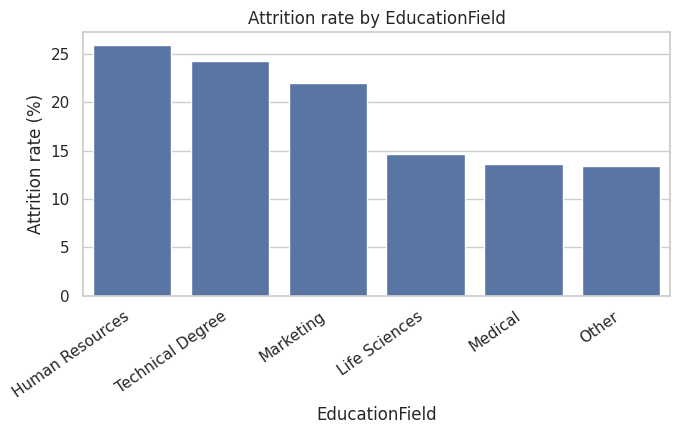

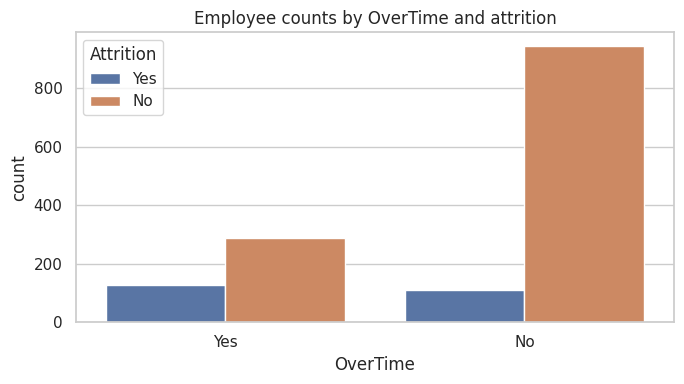

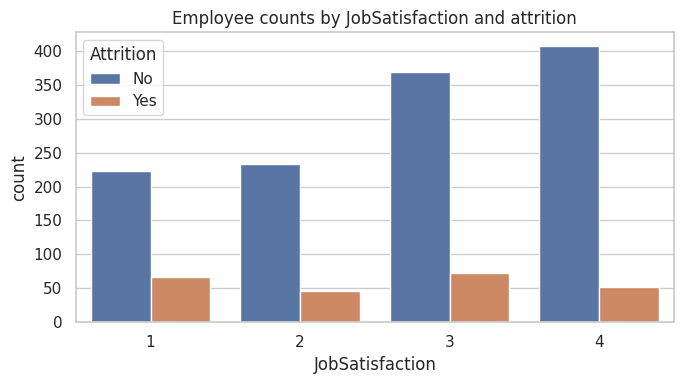

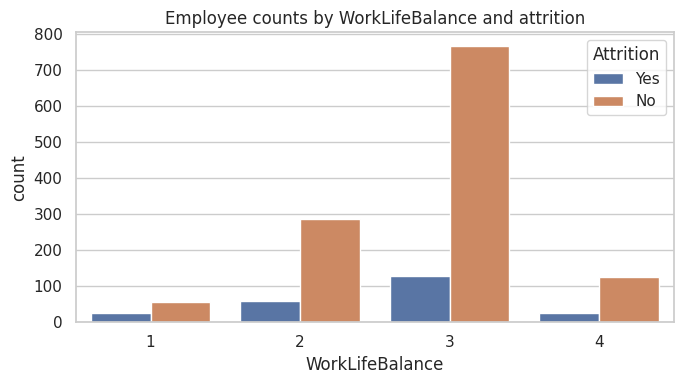

In [13]:
def group_attrition_rate(data, col):
    tab = pd.crosstab(data[col], data["Attrition"], normalize="index") * 100
    counts = pd.crosstab(data[col], data["Attrition"])
    result = pd.DataFrame(index=tab.index)
    result["employees"] = counts.sum(axis=1)
    result["attrition_rate_pct"] = tab["Yes"] if "Yes" in tab.columns else 0
    if "Yes" in counts.columns: result["attrition_yes"] = counts["Yes"]
    else: result["attrition_yes"] = 0
    return result.sort_values("attrition_rate_pct", ascending=False)

cat_candidates = ["Department", "JobRole", "OverTime", "BusinessTravel", "MaritalStatus", "Gender", "EducationField"]
available_cats = [c for c in cat_candidates if c in df.columns]
for col in available_cats:
    summary = group_attrition_rate(df, col)
    display(Markdown(f"### {col}: attrition rate by group"))
    display(summary.round(2))
    summary.to_csv(OUTPUT_DIR/f"attrition_by_{col}.csv")
    plt.figure(figsize=(max(7, len(summary)*0.8), 4.5))
    sns.barplot(x=summary.index.astype(str), y=summary["attrition_rate_pct"], errorbar=None)
    plt.title(f"Attrition rate by {col}")
    plt.ylabel("Attrition rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"bar_attrition_{col}.png", dpi=160)
    plt.show()

# At least two count plots
for col in [c for c in ["OverTime", "JobSatisfaction", "WorkLifeBalance"] if c in df.columns][:3]:
    plt.figure(figsize=(7,4))
    sns.countplot(data=df, x=col, hue="Attrition")
    plt.title(f"Employee counts by {col} and attrition")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"count_{col}.png", dpi=160)
    plt.show()


## 9. Attrition-based numerical comparisons

Compare stayers and leavers using mean and median summaries. Medians are especially useful for skewed fields such as MonthlyIncome. Differences are descriptive and should be interpreted alongside group sizes and distributions.


,variable,attrition,n,mean,median,std
0,Age,No,1233,37.56,36.0,8.89
1,Age,Yes,237,33.61,32.0,9.69
2,MonthlyIncome,No,1233,6832.74,5204.0,4818.21
3,MonthlyIncome,Yes,237,4787.09,3202.0,3640.21
4,DistanceFromHome,No,1233,8.92,7.0,8.01
5,DistanceFromHome,Yes,237,10.63,9.0,8.45
6,JobSatisfaction,No,1233,2.78,3.0,1.09
7,JobSatisfaction,Yes,237,2.47,3.0,1.12
8,WorkLifeBalance,No,1233,2.78,3.0,0.68
9,WorkLifeBalance,Yes,237,2.66,3.0,0.82


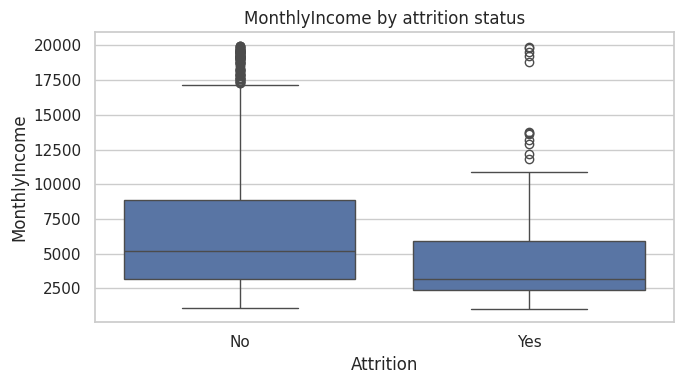

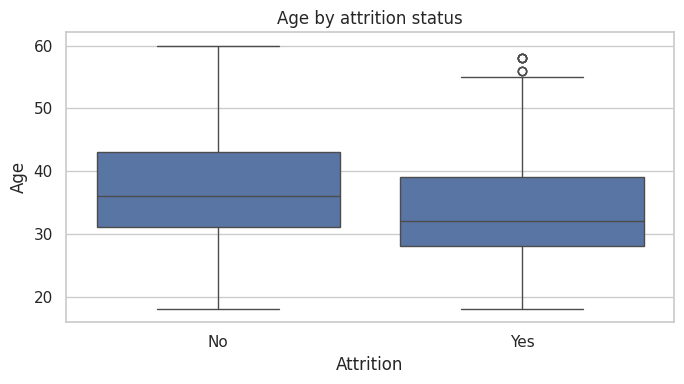

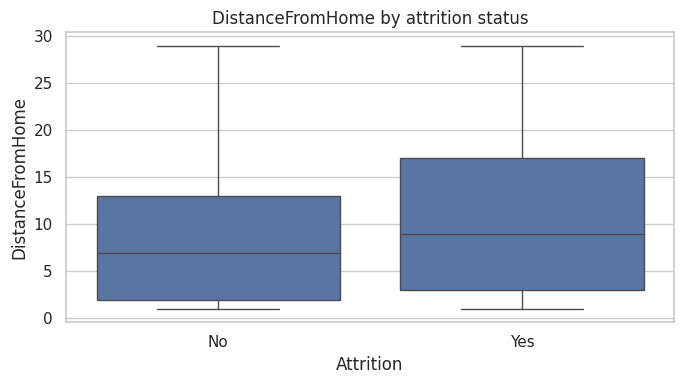

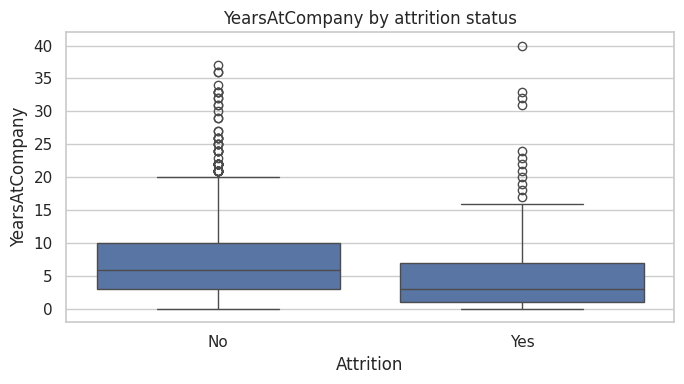

In [14]:
numeric_focus = [c for c in ["Age", "MonthlyIncome", "DistanceFromHome", "JobSatisfaction",
                             "WorkLifeBalance", "YearsAtCompany", "TotalWorkingYears",
                             "NumCompaniesWorked", "YearsSinceLastPromotion"] if c in df.columns]
comparison_rows = []
for col in numeric_focus:
    for status, sub in df.groupby("Attrition", dropna=False):
        comparison_rows.append({
            "variable": col, "attrition": status, "n": sub[col].notna().sum(),
            "mean": sub[col].mean(), "median": sub[col].median(), "std": sub[col].std()
        })
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(2))
comparison.to_csv(OUTPUT_DIR/"attrition_numeric_comparison.csv", index=False)

for col in [c for c in ["MonthlyIncome", "Age", "DistanceFromHome", "YearsAtCompany"] if c in df.columns][:4]:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df, x="Attrition", y=col, order=["No","Yes"])
    plt.title(f"{col} by attrition status")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"compare_{col}.png", dpi=160)
    plt.show()


## 10. Bivariate analysis — scatter plots

Scatter plots help explore relationships between numerical variables and attrition. Points may overlap; these plots are descriptive and not causal.


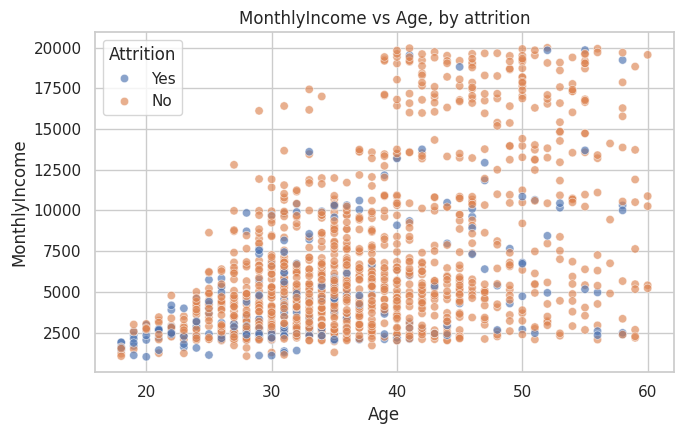

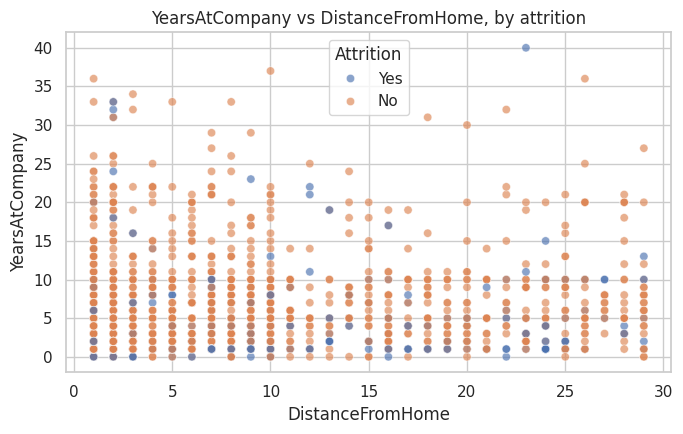

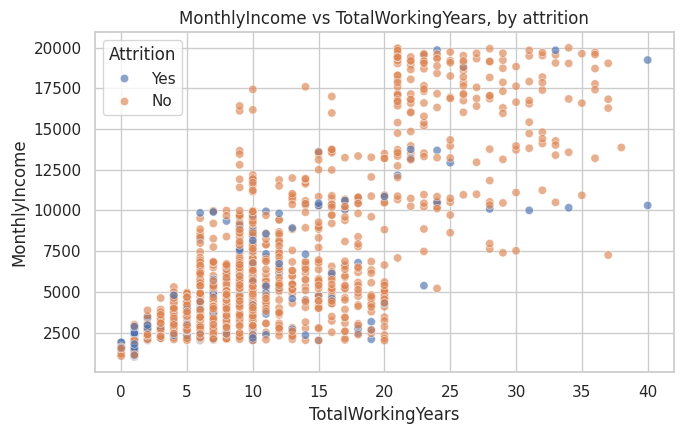

In [15]:
scatter_pairs = [("Age", "MonthlyIncome"), ("DistanceFromHome", "YearsAtCompany"),
                 ("TotalWorkingYears", "MonthlyIncome"), ("Age", "YearsAtCompany")]
scatter_pairs = [(x,y) for x,y in scatter_pairs if x in df.columns and y in df.columns][:3]
for x, y in scatter_pairs:
    plt.figure(figsize=(7,4.5))
    sns.scatterplot(data=df, x=x, y=y, hue="Attrition", alpha=.65)
    plt.title(f"{y} vs {x}, by attrition")
    plt.tight_layout()
    plt.savefig(FIG_DIR/f"scatter_{x}_{y}.png", dpi=160)
    plt.show()


## 11. Correlation heatmap and multivariate analysis

Pearson correlation is appropriate for linear associations among numeric variables, but ordinal survey scales and encoded categories require caution. Correlation does not establish causality. Constant columns and identifiers are excluded.


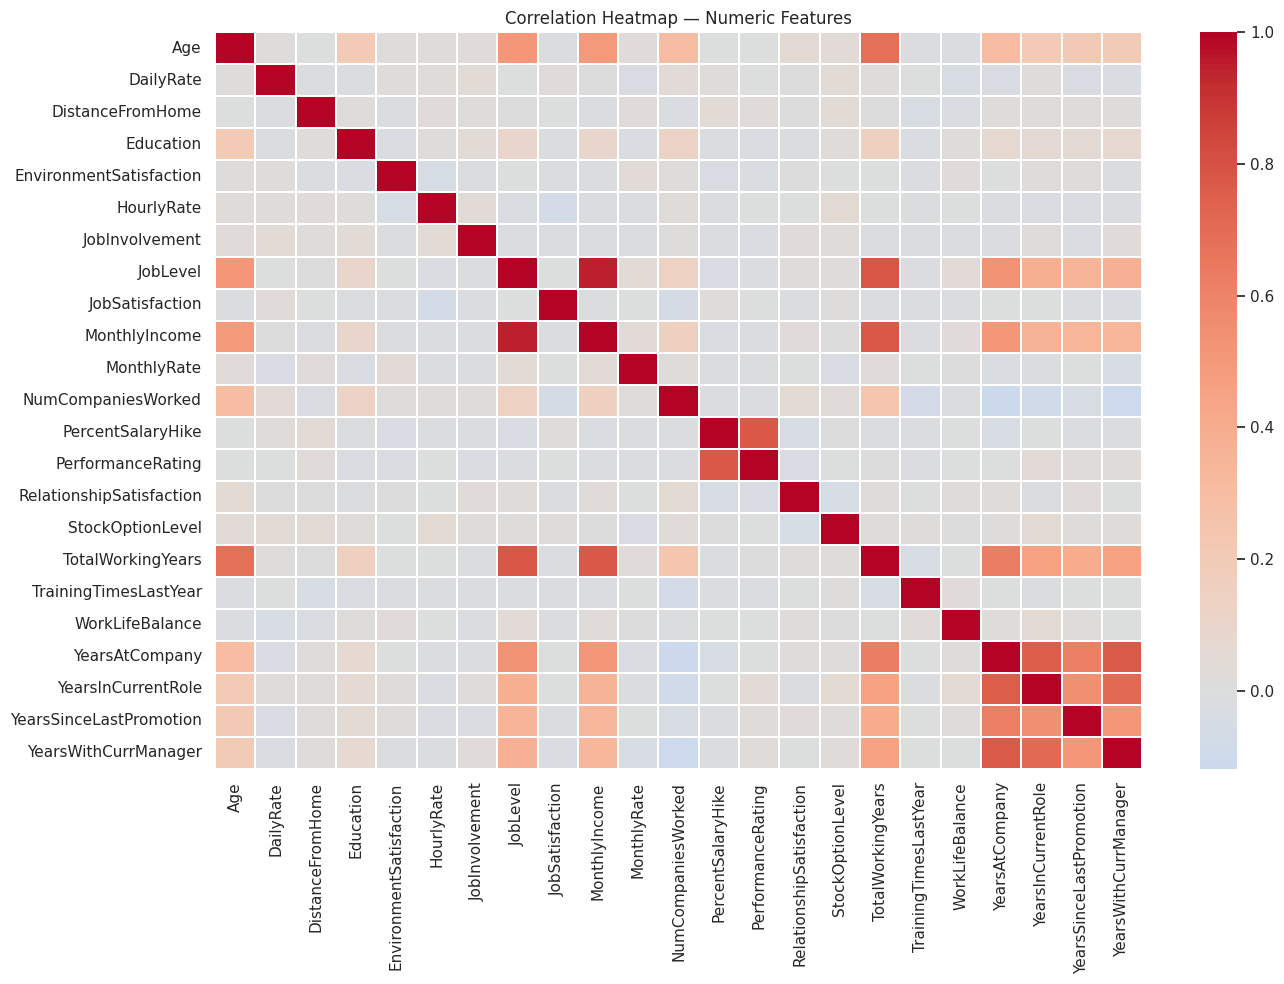

Attrition                 attrition_rate_pct
OverTime JobSatisfaction                    
No       1                             17.56
         2                              9.48
         3                              9.97
         4                              6.94
Yes      1                             35.71
         2                             37.68
         3                             33.88
         4                             21.13

In [16]:
num_df = df.select_dtypes(include=np.number).copy()
exclude_corr = [c for c in ["EmployeeNumber", "EmployeeCount", "StandardHours", "Over18"] if c in num_df.columns]
num_df = num_df.drop(columns=exclude_corr, errors="ignore")
corr = num_df.corr(numeric_only=True)
plt.figure(figsize=(14,10))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=.25)
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.savefig(FIG_DIR/"correlation_heatmap.png", dpi=180)
plt.show()

# Selected multivariate view if these fields are present
if all(c in df.columns for c in ["OverTime", "JobSatisfaction", "Attrition"]):
    pivot = pd.crosstab([df["OverTime"], df["JobSatisfaction"]], df["Attrition"], normalize="index")*100
    if "Yes" in pivot.columns:
        display(pivot[["Yes"]].rename(columns={"Yes":"attrition_rate_pct"}).round(2))


## 12. Time-series analysis applicability

The provided IBM HR attrition dataset does not contain a reliable employee event date or monthly attrition timestamp. Therefore, a time-series chart is **not applicable** to the dataset as supplied. A trend chart should not be fabricated. If a real date field becomes available in a future version, attrition can be aggregated by month or quarter.


In [17]:
date_cols = [c for c in df.columns if "date" in c.lower() or "month" in c.lower() and df[c].dtype == "datetime64[ns]"]
print("Potential date columns:", date_cols if date_cols else "None found; time-series chart not applicable.")


Potential date columns: None found; time-series chart not applicable.


## 13. Business insights and recommendations

The next cell generates dataset-specific findings after the notebook runs. Use these outputs to write a careful narrative. Avoid presenting an association as a cause or claiming that an observed difference is statistically or practically important without further validation.


In [18]:
insights = []
insights.append(f"Overall attrition: {attrition_rate:.2f}% ({int((df['Attrition']=='Yes').sum())} leavers out of {len(df)} employee records).")

for col in ["Department", "JobRole", "OverTime", "BusinessTravel"]:
    if col in df.columns:
        s = group_attrition_rate(df, col)
        if len(s):
            top = s.iloc[0]
            insights.append(f"Highest observed attrition rate by {col}: {s.index[0]} ({top['attrition_rate_pct']:.1f}%; n={int(top['employees'])}). Check group size before drawing conclusions.")

for col in ["MonthlyIncome", "Age", "DistanceFromHome", "JobSatisfaction", "WorkLifeBalance", "YearsAtCompany"]:
    if col in df.columns:
        med = df.groupby("Attrition")[col].median()
        if "Yes" in med.index and "No" in med.index:
            insights.append(f"Median {col}: leavers={med['Yes']:.2f}; stayers={med['No']:.2f}.")

print("DATA-GENERATED FINDINGS")
for item in insights:
    print("•", item)

recommendations = [
    "Review overtime workload and staffing practices; compare attrition rates and group sizes before changing policy.",
    "Investigate high-attrition job roles with HR interviews and role-specific retention analysis.",
    "Evaluate compensation bands and career progression using pay equity and job-level context rather than salary alone.",
    "Review job satisfaction and work-life balance feedback alongside manager and team context.",
    "Use voluntary, privacy-respecting employee feedback and repeat analyses over time if dated records become available.",
    "Do not use these descriptive patterns to make individual employment decisions; validate findings and assess fairness."
]
print("\nPRACTICAL RECOMMENDATIONS")
for item in recommendations:
    print("•", item)

with open(OUTPUT_DIR/"insights_and_recommendations.txt", "w", encoding="utf-8") as f:
    f.write("DATA-GENERATED FINDINGS\n" + "\n".join("• "+x for x in insights))
    f.write("\n\nPRACTICAL RECOMMENDATIONS\n" + "\n".join("• "+x for x in recommendations))


DATA-GENERATED FINDINGS
• Overall attrition: 16.12% (237 leavers out of 1470 employee records).
• Highest observed attrition rate by Department: Sales (20.6%; n=446). Check group size before drawing conclusions.
• Highest observed attrition rate by JobRole: Sales Representative (39.8%; n=83). Check group size before drawing conclusions.
• Highest observed attrition rate by OverTime: Yes (30.5%; n=416). Check group size before drawing conclusions.
• Highest observed attrition rate by BusinessTravel: Travel_Frequently (24.9%; n=277). Check group size before drawing conclusions.
• Median MonthlyIncome: leavers=3202.00; stayers=5204.00.
• Median Age: leavers=32.00; stayers=36.00.
• Median DistanceFromHome: leavers=9.00; stayers=7.00.
• Median JobSatisfaction: leavers=3.00; stayers=3.00.
• Median WorkLifeBalance: leavers=3.00; stayers=3.00.
• Median YearsAtCompany: leavers=3.00; stayers=6.00.

PRACTICAL RECOMMENDATIONS
• Review overtime workload and staffing practices; compare attrition rat

## 14. Export cleaned data and final deliverables

This final cell saves a cleaned CSV, a PDF EDA report, and a PowerPoint deck. Run it only after all analysis cells have completed. Outputs are created in `outputs/`.


In [21]:
# Save cleaned data
df.to_csv(OUTPUT_DIR/"cleaned_employee_attrition.csv", index=False)

# Build a PDF report from the live analysis results
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors

pdf_path = OUTPUT_DIR/"EDA_Report.pdf"
styles = getSampleStyleSheet()
story = [
    Paragraph("Employee Attrition & Workforce Analytics using Python", styles["Title"]),
    Paragraph("Exploratory Data Analysis Report", styles["Heading2"]),
    Spacer(1, 10),
    Paragraph(f"Dataset size: {len(df):,} rows × {df.shape[1]} columns.", styles["BodyText"]),
    Paragraph(f"Overall attrition rate: {attrition_rate:.2f}% ({int((df['Attrition']=='Yes').sum()):,} employees marked Yes).", styles["BodyText"]),
    Spacer(1, 10),
    Paragraph("1. Objective and business questions", styles["Heading1"]),
    Paragraph("This analysis explores employee attrition by department, job role, overtime, income, satisfaction, distance from home, age, work-life balance, and tenure. The objective is to identify descriptive patterns that may help guide further HR investigation.", styles["BodyText"]),
    Paragraph("2. Data quality", styles["Heading1"]),
    Paragraph(f"Exact duplicate rows detected: {exact_duplicates}. Missing values detected: {int(df.isna().sum().sum())}. Constant columns: {', '.join(constant_cols) if constant_cols else 'None'}. Potential outliers are flagged using the 1.5×IQR rule and are not automatically removed.", styles["BodyText"]),
    Paragraph("3. Key findings", styles["Heading1"]),
]
for item in insights:
    story.append(Paragraph("• " + item.replace("&","&amp;"), styles["BodyText"]))
    story.append(Spacer(1, 4))
story += [Paragraph("4. Recommendations", styles["Heading1"])]
for item in recommendations:
    story.append(Paragraph("• " + item.replace("&","&amp;"), styles["BodyText"]))
    story.append(Spacer(1, 4))
story += [
    Paragraph("5. Limitations", styles["Heading1"]),
    Paragraph("This is a cross-sectional, observational dataset. Findings describe associations and do not prove causality. The dataset may not represent every employer or workforce. Some fields are ordinal ratings, so numerical summaries should be interpreted cautiously. There is no suitable date field for time-series analysis. Attrition-rate comparisons should be reviewed with group sizes and business context.", styles["BodyText"]),
    Paragraph("6. Reproducibility", styles["Heading1"]),
    Paragraph("All results are generated from the CSV loaded in this notebook. See the notebook for cleaning checks, plots, group-by tables, correlation analysis, and outlier diagnostics.", styles["BodyText"])
]
SimpleDocTemplate(str(pdf_path), pagesize=A4, rightMargin=42, leftMargin=42, topMargin=42, bottomMargin=42).build(story)
print("Created:", pdf_path)

# Build a 7-slide PowerPoint summary
prs = Presentation()
def add_title_slide(title, subtitle):
    slide = prs.slides.add_slide(prs.slide_layouts[0])
    slide.shapes.title.text = title
    slide.placeholders[1].text = subtitle
def add_bullets(title, bullets):
    slide = prs.slides.add_slide(prs.slide_layouts[1])
    slide.shapes.title.text = title
    tf = slide.placeholders[1].text_frame
    tf.clear()
    for i, item in enumerate(bullets):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = item
        p.level = 0
        p.font.size = Pt(20)
add_title_slide("Employee Attrition & Workforce Analytics", "Exploratory Data Analysis | Python | IBM HR Analytics dataset")
add_bullets("Project objective", [
    "Understand patterns associated with employee attrition.",
    "Explore department, job role, overtime, income, satisfaction, distance, age, and work-life balance.",
    "Provide practical, evidence-aware recommendations for HR."
])
add_bullets("Dataset & quality checks", [
    f"{len(df):,} employee records and {df.shape[1]} columns.",
    f"Overall attrition rate: {attrition_rate:.2f}%.",
    f"Exact duplicate rows: {exact_duplicates}; missing cells: {int(df.isna().sum().sum())}.",
    "Potential outliers are flagged, not automatically deleted."
])
add_bullets("Key observed patterns", insights[:5] if insights else ["Run the notebook to generate findings."])
add_bullets("What HR can investigate", [
    "Review overtime demands and workload distribution.",
    "Explore retention barriers in job roles with elevated observed rates.",
    "Pair satisfaction and work-life balance results with employee feedback.",
    "Review compensation with job level, tenure, and pay equity context."
])
add_bullets("Recommendations", recommendations[:5])
add_bullets("Limitations & next steps", [
    "Observational analysis; associations do not prove causality.",
    "Group sizes and business context matter when comparing attrition rates.",
    "No appropriate date field is available for time-series analysis.",
    "Validate findings with HR stakeholders and repeat with time-stamped data if available."
])
ppt_path = OUTPUT_DIR/"Presentation.pptx"
prs.save(ppt_path)
print("Created:", ppt_path)
print("All outputs:", sorted(os.listdir(OUTPUT_DIR)))


Created: outputs/EDA_Report.pdf
Created: outputs/Presentation.pptx
All outputs: ['EDA_Report.pdf', 'Presentation.pptx', 'attrition_by_BusinessTravel.csv', 'attrition_by_Department.csv', 'attrition_by_EducationField.csv', 'attrition_by_Gender.csv', 'attrition_by_JobRole.csv', 'attrition_by_MaritalStatus.csv', 'attrition_by_OverTime.csv', 'attrition_numeric_comparison.csv', 'cleaned_employee_attrition.csv', 'data_dictionary.csv', 'figures', 'insights_and_recommendations.txt', 'outlier_summary.csv']
